# Chương 1 — EDA chuyên sâu dữ liệu bảng: Adult Census Income

## Mục tiêu

Chương này kiểm tra điều kiện dữ liệu, phân phối từng biến số, tương quan Pearson/Spearman, cấu trúc missing và giả thuyết MCAR. Mọi kết luận phải dựa trên kết quả notebook chạy thực tế, không điền số liệu giả định.

**Nguồn dữ liệu:** [Adult Census Income trên Hugging Face](https://huggingface.co/datasets/scikit-learn/adult-census-income). Bộ dữ liệu có 32.561 quan sát, 14 thuộc tính đầu vào và nhãn thu nhập. Dấu `?` trong ba thuộc tính phân loại được chuẩn hóa thành giá trị thiếu `NaN`.

> Lưu ý: dữ liệu mô tả hồ sơ điều tra dân số Hoa Kỳ năm 1994; không được diễn giải kết quả như quan hệ nhân quả hoặc áp dụng trực tiếp cho bối cảnh hiện tại.

In [ ]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
REPO_ROOT = next((p for p in _candidates if (p / "src").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục src/. Hãy mở notebook từ thư mục repository gốc.")
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.data_loading import load_adult_dataset
from src.tabular_analysis import split_feature_types

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("Repository:", REPO_ROOT)

Repository: /content/data-preprocessing-project


## 1. Tải dữ liệu và kiểm tra điều kiện đề bài

Bộ dữ liệu được tải tự động từ Hugging Face ở lần chạy đầu tiên và lưu cache bên ngoài mã nguồn. Không đưa dữ liệu thô vào GitHub.

In [ ]:
df = load_adult_dataset()
X, numeric_cols, categorical_cols = split_feature_types(df, target="income")

n_rows, n_features = len(df), X.shape[1]
missing_rate = X.isna().mean().sort_values(ascending=False)
validation = {
    "records >= 10,000": n_rows >= 10_000,
    "predictor attributes >= 10": n_features >= 10,
    "both numerical and categorical": len(numeric_cols) > 0 and len(categorical_cols) > 0,
    "at least one missing rate >= 5%": bool((missing_rate >= 0.05).any()),
}
print(f"Shape: {df.shape}; predictors: {n_features}; numeric: {len(numeric_cols)}; categorical: {len(categorical_cols)}")
display(pd.DataFrame({"requirement": validation.keys(), "passed": validation.values()}))
display(missing_rate.rename("missing_rate").to_frame().style.format({"missing_rate": "{:.2%}"}))
assert all(validation.values()), "Dataset hiện không đạt các ngưỡng bắt buộc của đề bài."

README.md:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

adult.csv:   0%|          | 0.00/4.10M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/32561 [00:00<?, ? examples/s]

Shape: (32561, 15); predictors: 14; numeric: 6; categorical: 8


,requirement,passed
0,"records >= 10,000",True
1,predictor attributes >= 10,True
2,both numerical and categorical,True
3,at least one missing rate >= 5%,True


,missing_rate
occupation,5.66%
workclass,5.64%
native_country,1.79%
education,0.00%
fnlwgt,0.00%
age,0.00%
marital_status,0.00%
education_num,0.00%
race,0.00%
relationship,0.00%


## 2. Tổng quan cấu trúc và thống kê mô tả

- `shape`, kiểu dữ liệu và nhãn cho biết quy mô, cấu trúc tổng quát.
- `describe` tóm tắt trung tâm, độ phân tán và các phân vị của biến số.
- Kiểm tra nhãn trước khi mô hình hóa; không dùng biến mục tiêu làm đầu vào.

In [ ]:
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df[numeric_cols].describe().T)
print("Target distribution:")
display(df["income"].value_counts(dropna=False).rename("count").to_frame())

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,<NA>,77053,HS-grad,9,Widowed,<NA>,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,<NA>,186061,Some-college,10,Widowed,<NA>,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


,dtype
age,int64
workclass,string[python]
fnlwgt,int64
education,string[python]
education_num,int64
marital_status,string[python]
occupation,string[python]
relationship,string[python]
race,string[python]
sex,string[python]


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


Target distribution:


,count
income,
<=50K,24720
>50K,7841


## 3. Kiểm định phân phối từng thuộc tính số

Với mỗi biến có `n > 5.000`, sử dụng kiểm định D’Agostino–Pearson (`scipy.stats.normaltest`).

- $H_0$: dữ liệu phù hợp với phân phối chuẩn.
- $H_1$: dữ liệu không phù hợp với phân phối chuẩn.
- Quy ước $\alpha=0.05$: `p < 0.05` là bằng chứng chống lại giả thuyết chuẩn.

Với cỡ mẫu lớn, kiểm định rất nhạy; cần kết hợp histogram/KDE và không chỉ dựa vào p-value.

$$K^2=Z_1^2+Z_2^2\ \sim\ \chi^2_2,\qquad b_1=\frac{m_3}{m_2^{3/2}},\quad b_2=\frac{m_4}{m_2^{2}},\quad m_k=\frac1n\sum_{i=1}^n(x_i-\bar x)^k$$

$Z_1$ và $Z_2$ là các biến đổi chuẩn hóa của độ lệch $b_1$ và độ nhọn $b_2$ (D’Agostino–Pearson). Shapiro–Wilk được dùng khi $n\le 5000$.

In [ ]:
from scipy.stats import normaltest

normality_rows = []
for col in numeric_cols:
    values = df[col].dropna().astype(float)
    if len(values) > 5_000:
        statistic, p_value = normaltest(values)
        test_name = "D'Agostino-Pearson"
    else:
        from scipy.stats import shapiro
        statistic, p_value = shapiro(values.sample(min(len(values), 5_000), random_state=RANDOM_SEED))
        test_name = "Shapiro-Wilk"
    normality_rows.append({
        "feature": col, "n": len(values), "test": test_name,
        "statistic": float(statistic), "p_value": float(p_value),
        "decision": "Không chuẩn (bác bỏ H0)" if p_value < 0.05 else "Chưa đủ bằng chứng bác bỏ chuẩn"
    })
normality_results = pd.DataFrame(normality_rows).sort_values("p_value")
display(normality_results)

,feature,n,test,statistic,p_value,decision
0,age,32561,D'Agostino-Pearson,1526.010846,0.000000e+00,Không chuẩn (bác bỏ H0)
1,fnlwgt,32561,D'Agostino-Pearson,10662.513695,0.000000e+00,Không chuẩn (bác bỏ H0)
3,capital_gain,32561,D'Agostino-Pearson,55096.550375,0.000000e+00,Không chuẩn (bác bỏ H0)
4,capital_loss,32561,D'Agostino-Pearson,29331.399856,0.000000e+00,Không chuẩn (bác bỏ H0)
5,hours_per_week,32561,D'Agostino-Pearson,2508.918440,0.000000e+00,Không chuẩn (bác bỏ H0)
2,education_num,32561,D'Agostino-Pearson,817.164145,3.589720e-178,Không chuẩn (bác bỏ H0)


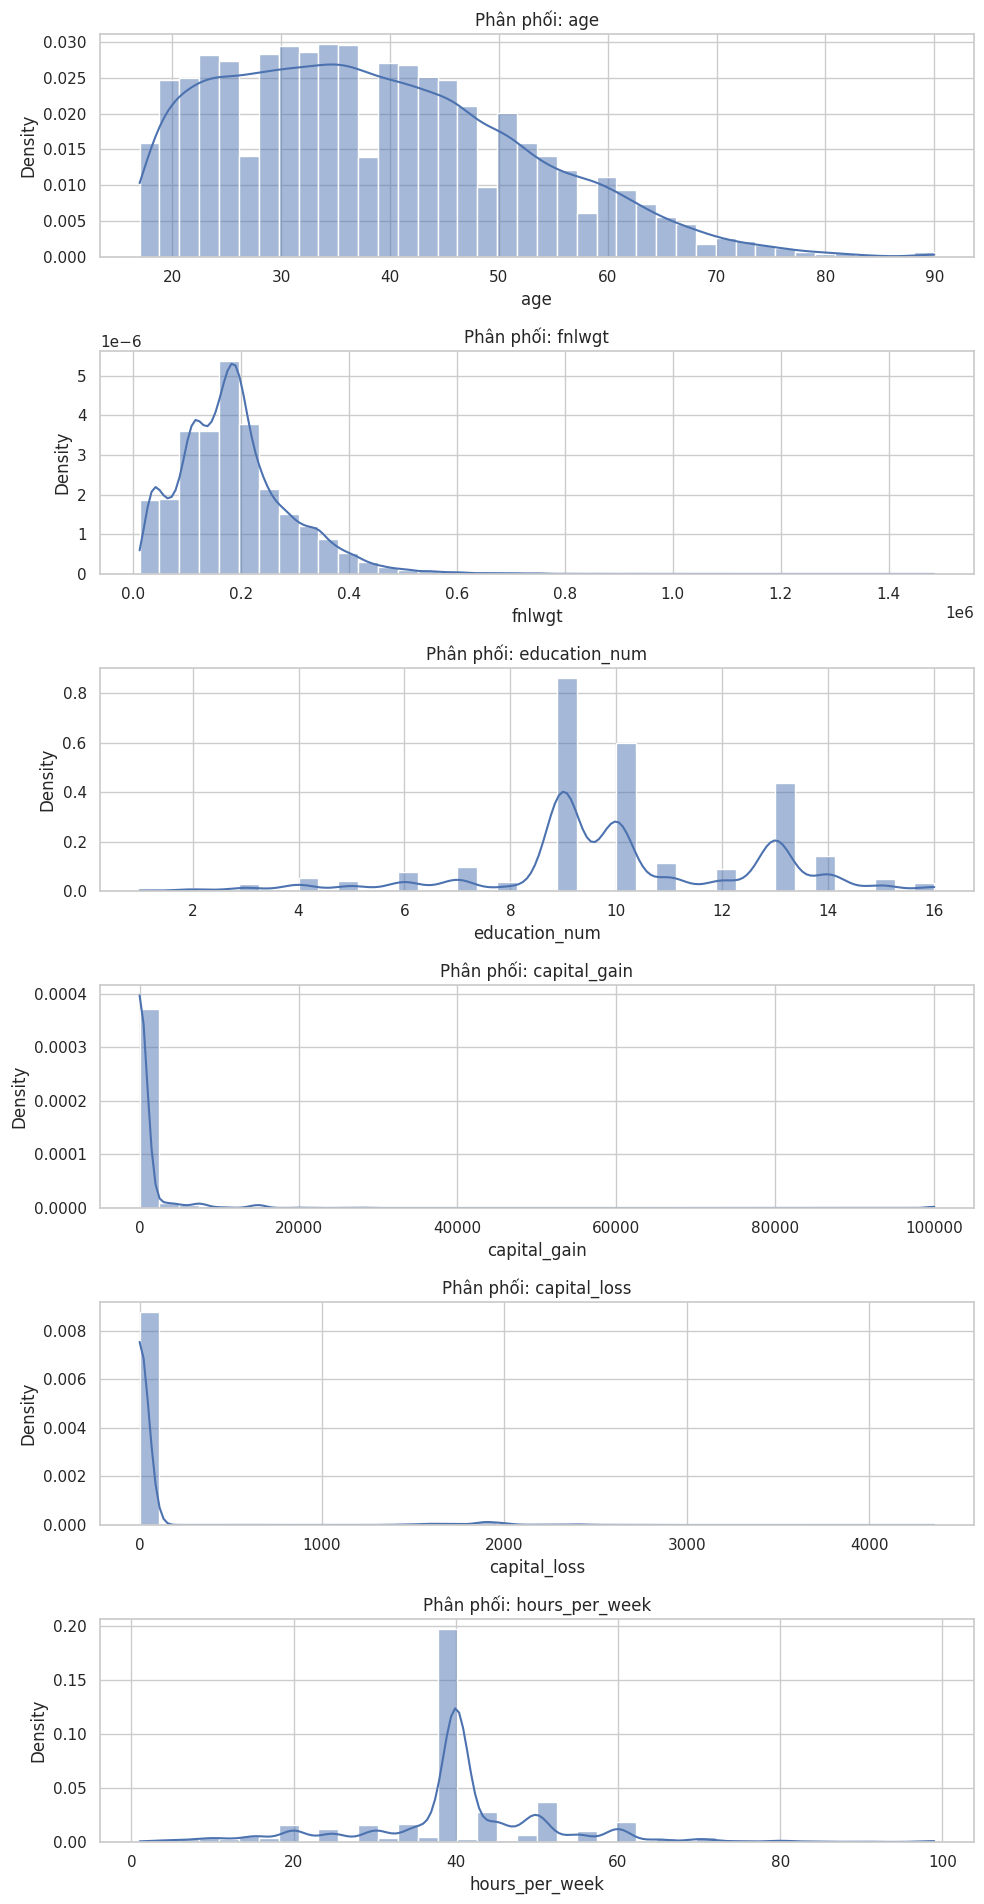

In [ ]:
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(10, 3.2 * len(numeric_cols)))
if len(numeric_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=True, stat="density", ax=ax)
    ax.set_title(f"Phân phối: {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Phân tích kết quả:** đối chiếu bảng kiểm định với hình phân phối. Các biến vốn lệch mạnh (ví dụ biến có nhiều giá trị 0 và đuôi phải dài) thường không phù hợp giả định chuẩn. Đây là một căn cứ để cân nhắc Robust Scaling hoặc Quantile Transform ở chương tiếp theo; không được tự động kết luận rằng một scaler “tốt nhất” chỉ từ kiểm định chuẩn.

## 4. Phân tích tương quan Pearson và Spearman

- Pearson đo tương quan tuyến tính giữa hai biến số.
- Spearman đo tương quan đơn điệu dựa trên thứ hạng, ít nhạy hơn với ngoại lệ và quan hệ phi tuyến đơn điệu.
- Cặp có $|r| > 0.9$ được đánh dấu để xem xét đa cộng tuyến; tương quan cao không tự động chứng minh một biến phải bị xóa.

$$r=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2\,\sum_i(y_i-\bar y)^2}},\qquad \rho_s=r\bigl(\operatorname{rank}(x),\operatorname{rank}(y)\bigr)$$

$r$ là hệ số Pearson; $\rho_s$ là hệ số Spearman, tức Pearson áp dụng trên thứ hạng.

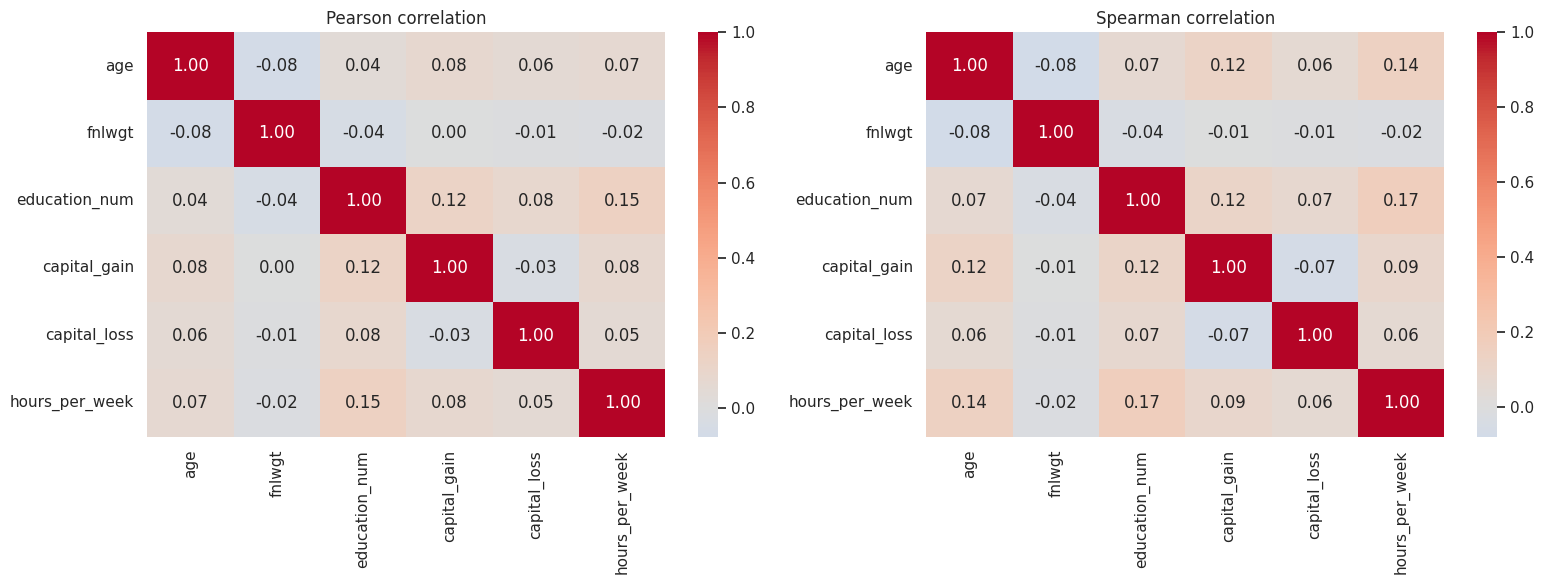

Các cặp có |Pearson r| > 0.9:


,note
0,Không phát hiện cặp vượt ngưỡng 0.9.


In [ ]:
pearson_corr = df[numeric_cols].corr(method="pearson")
spearman_corr = df[numeric_cols].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout(); plt.show()

strong_pairs = []
for i, left in enumerate(numeric_cols):
    for right in numeric_cols[i + 1:]:
        value = pearson_corr.loc[left, right]
        if abs(value) > 0.9:
            strong_pairs.append({"feature_1": left, "feature_2": right, "pearson_r": value})
strong_correlations = pd.DataFrame(strong_pairs, columns=["feature_1", "feature_2", "pearson_r"])
print("Các cặp có |Pearson r| > 0.9:")
display(strong_correlations if not strong_correlations.empty else pd.DataFrame({"note": ["Không phát hiện cặp vượt ngưỡng 0.9."]}))

## 5. Phân tích dữ liệu thiếu bằng missingno

Ma trận missingno cho thấy vị trí các ô thiếu theo từng quan sát. Bảng tỷ lệ missing dùng để xác định cột ảnh hưởng lớn nhất. Giá trị `?` đã được chuyển về `NaN` trong hàm tải dữ liệu.

,missing_count,missing_rate
occupation,1843,5.66%
workclass,1836,5.64%
native_country,583,1.79%
education,0,0.00%
fnlwgt,0,0.00%
age,0,0.00%
marital_status,0,0.00%
education_num,0,0.00%
race,0,0.00%
relationship,0,0.00%


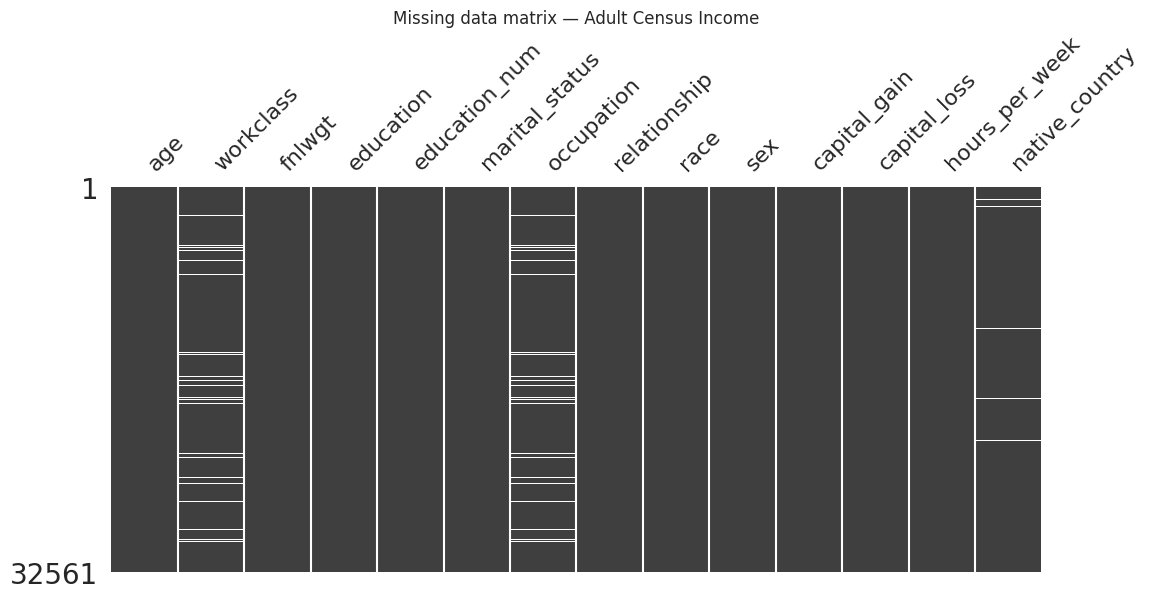

In [ ]:
missing_table = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_rate": X.isna().mean(),
}).sort_values("missing_rate", ascending=False)
display(missing_table.style.format({"missing_rate": "{:.2%}"}))

import missingno as msno
fig = msno.matrix(X, figsize=(12, 5), sparkline=False)
plt.title("Missing data matrix — Adult Census Income")
plt.show()

## 6. Little’s MCAR test

Kiểm định Little có giả thuyết không $H_0$: dữ liệu thiếu hoàn toàn ngẫu nhiên (MCAR). Nếu `p < 0.05`, bác bỏ MCAR. Do dữ liệu chứa biến phân loại, notebook ordinal-code các biến phân loại để có ma trận số đầu vào cho `pyampute`; đây là xấp xỉ cần nêu rõ, vì kiểm định Little dựa trên giả định phân phối đa biến và mã hóa thứ bậc không bảo toàn khoảng cách giữa category.

$$d^2=\sum_{j=1}^{J}n_j\left(\bar{\mathbf x}_j^{\,obs}-\hat{\boldsymbol\mu}^{\,obs}_j\right)^{\!\top}\hat\Sigma_j^{-1}\left(\bar{\mathbf x}_j^{\,obs}-\hat{\boldsymbol\mu}^{\,obs}_j\right)\ \sim\ \chi^2_{\,\sum_j k_j-p}$$

$J$ là số mẫu hình thiếu dữ liệu, $n_j$ là số dòng của mẫu hình $j$, $k_j$ là số biến quan sát được trong mẫu hình đó, $p$ là tổng số biến. $\hat{\boldsymbol\mu}$ và $\hat\Sigma$ được ước lượng bằng EM.

In [ ]:
from src.tabular_analysis import little_mcar_test

# A reproducible sample keeps the statistical test responsive on a laptop.
mcar_input = df.sample(min(len(df), 8_000), random_state=RANDOM_SEED).copy()
little_mcar_p_value = little_mcar_test(mcar_input, target="income")
print(f"Little's MCAR test p-value = {little_mcar_p_value:.6g}")
if little_mcar_p_value < 0.05:
    print("Kết luận ở alpha=0.05: bác bỏ H0; có bằng chứng dữ liệu không MCAR.")
else:
    print("Kết luận ở alpha=0.05: chưa đủ bằng chứng bác bỏ H0; không đồng nghĩa đã chứng minh MCAR.")

Little's MCAR test p-value = 1.12388e-66
Kết luận ở alpha=0.05: bác bỏ H0; có bằng chứng dữ liệu không MCAR.


## 7. Phân biệt MCAR, MAR và MNAR — bằng chứng và giới hạn

- **MCAR:** xác suất thiếu không phụ thuộc cả dữ liệu đã quan sát lẫn chưa quan sát.
- **MAR:** sau khi điều kiện hóa theo biến đã quan sát, xác suất thiếu không còn phụ thuộc giá trị đang thiếu.
- **MNAR:** xác suất thiếu còn phụ thuộc chính giá trị chưa quan sát.

Little’s test chỉ kiểm tra giả thuyết MCAR; nó không tự phân biệt MAR với MNAR. Bước tiếp theo kiểm tra xem trạng thái thiếu ở các cột chính có liên hệ với các thuộc tính quan sát được hay không. Liên hệ có ý nghĩa là bằng chứng ủng hộ khả năng MAR, nhưng không chứng minh MAR. MNAR cần thông tin ngoài dữ liệu hoặc giả định chuyên môn.

In [ ]:
from scipy.stats import chi2_contingency

missingness_associations = []
for missing_col in [c for c in X.columns if X[c].isna().any()]:
    indicator = X[missing_col].isna().astype(int)
    for observed_col in X.columns:
        if observed_col == missing_col:
            continue
        observed = X[observed_col]
        if pd.api.types.is_numeric_dtype(observed):
            # Bin numerical covariates into quantiles for a chi-square association check.
            grouped = pd.qcut(observed, q=5, duplicates="drop")
        else:
            grouped = observed.astype("string").fillna("__MISSING__")
            top = grouped.value_counts().head(12).index
            grouped = grouped.where(grouped.isin(top), "__OTHER__")
        table = pd.crosstab(indicator, grouped)
        if table.shape[0] == 2 and table.shape[1] >= 2:
            chi2_stat, p_value, dof, _ = chi2_contingency(table)
            missingness_associations.append({
                "missing_column": missing_col,
                "observed_covariate": observed_col,
                "chi2": float(chi2_stat), "dof": int(dof), "p_value": float(p_value)
            })
association_results = pd.DataFrame(missingness_associations).sort_values("p_value")
display(association_results.head(20))

,missing_column,observed_covariate,chi2,dof,p_value
5,workclass,occupation,32429.938154,12,0.000000e+00
12,occupation,workclass,32561.000000,8,0.000000e+00
20,occupation,hours_per_week,1007.730039,3,3.786560e-218
9,workclass,hours_per_week,1001.243982,3,9.666625e-217
11,occupation,age,847.200219,4,4.579204e-182
0,workclass,age,842.244000,4,5.425968e-181
17,occupation,relationship,365.416703,5,8.381720e-77
6,workclass,relationship,356.381367,5,7.397951e-75
30,native_country,race,323.812363,4,7.888172e-69
16,occupation,marital_status,302.158009,6,2.820650e-62


In [ ]:
from scipy.stats import mannwhitneyu

print("Số dòng thiếu đồng thời occupation và workclass:",
      (df["occupation"].isna() & df["workclass"].isna()).sum())

for col in ["occupation", "workclass", "native_country"]:
    miss = df[col].isna()
    for v in ["age", "hours_per_week", "education_num"]:
        _, p = mannwhitneyu(df.loc[miss, v], df.loc[~miss, v])
        print(f"{col} thiếu vs {v}: p = {p:.3g}")

Số dòng thiếu đồng thời occupation và workclass: 1836
occupation thiếu vs age: p = 0.55
occupation thiếu vs hours_per_week: p = 6.06e-187
occupation thiếu vs education_num: p = 6.81e-36
workclass thiếu vs age: p = 0.722
workclass thiếu vs hours_per_week: p = 1.1e-185
workclass thiếu vs education_num: p = 3.59e-35
native_country thiếu vs age: p = 0.457
native_country thiếu vs hours_per_week: p = 0.0384
native_country thiếu vs education_num: p = 2.7e-08


In [ ]:
num_cols = df.select_dtypes("number").columns
print(pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurt()}).round(3))

                  skew  kurtosis
age              0.559    -0.166
fnlwgt           1.447     6.219
education_num   -0.312     0.623
capital_gain    11.954   154.799
capital_loss     4.595    20.377
hours_per_week   0.228     2.917


### Kết luận EDA

**1. Tỷ lệ thiếu.** Hai thuộc tính đạt ngưỡng 5%: `occupation` (5,66%) và `workclass` (5,64%). `native_country` thiếu 1,79%, dưới ngưỡng nhưng vẫn được giữ lại cho các phân tích sau. Các biến còn lại không thiếu.

**2. Kiểm định phân phối (D'Agostino–Pearson, n = 32.561).** Sáu biến số đều bác bỏ H0, tức không tuân theo phân phối chuẩn: `age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss`, `hours_per_week`. Với n lớn, p-value gần như luôn nhỏ, nên mức lệch thực tế cần đọc qua skewness và kurtosis:
- Lệch nhất là `capital_gain` (skew 11,95; kurtosis 154,80) và `capital_loss` (skew 4,60; kurtosis 20,38). Hai biến này có nhiều giá trị bằng 0 và đuôi phải rất dài, nên ở chương 2 cần ưu tiên các phương pháp chuẩn hóa bền vững như Robust hoặc Quantile.
- `fnlwgt` lệch vừa phải (skew 1,45) nhưng đuôi dày (kurtosis 6,22).
- `age`, `hours_per_week` và `education_num` lệch nhẹ (|skew| < 0,6). Với các biến này, kết quả kiểm định chủ yếu phản ánh cỡ mẫu lớn.
- Các p-value hiển thị `0.000000e+00` là do máy làm tròn giá trị quá nhỏ, không phải bằng 0 thật.

**3. Tương quan.**
- Trên heatmap Pearson và Spearman, mọi hệ số giữa các cặp biến số đều có |r| < 0,2, nên không có cặp nào vượt ngưỡng 0,9 và không có dấu hiệu đa cộng tuyến giữa các biến số. Cặp tương quan mạnh nhất là `education_num` với `hours_per_week` (Pearson 0,15; Spearman 0,17), cùng chiều dương và yếu. Các cặp khác đều dưới 0,15 theo Pearson, và phần lớn gần 0.

- Hai phương pháp cho cùng dấu ở tất cả các cặp. Với các cặp có liên quan đến `age`, Spearman thường cao hơn Pearson (ví dụ `age` với `hours_per_week`: 0,14 so với 0,07; `age` với `capital_gain`: 0,12 so với 0,08). Điều này gợi ý mối quan hệ có tính đơn điệu nhưng không hoàn toàn tuyến tính, và có thể bị ảnh hưởng bởi độ lệch của các biến như `capital_gain`. Tuy nhiên chênh lệch này nhỏ nên không đáng kể ở mức độ tương quan hiện tại.

- Heatmap chỉ gồm sáu biến số. `education` (dạng chữ) không có trong ma trận, và `education_num` là bản mã hóa số của nó. Vì vậy ma trận không phát hiện được sự trùng lặp thông tin này. Khi xây dựng mô hình cần loại bỏ một trong hai, và sẽ kiểm tra lại đa cộng tuyến bằng VIF ở chương 2 sau khi mã hóa các biến phân loại.

**4. Little's MCAR.** p = 1,12 × 10⁻⁶⁶ < 0,05, nên bác bỏ H0: dữ liệu thiếu không phải MCAR. Kiểm định được chạy trên mẫu ngẫu nhiên 8.000 dòng (seed 42) và trên các biến phân loại đã mã hóa ordinal, nên p-value chỉ mang tính xấp xỉ.

**5. Thảo luận MAR và MNAR.**
- Dòng thiếu `occupation` và `workclass` khác dòng đủ ở `hours_per_week` và `education_num` (p < 10⁻³⁴ với cả hai biến, và p ≤ 1,1 × 10⁻¹⁸⁵ với `hours_per_week`), nhưng không khác ở `age` (p = 0,55 và 0,72).
- Dòng thiếu `native_country` khác ở `education_num` (p = 2,7 × 10⁻⁸) và `hours_per_week` (p = 0,038), không khác ở `age` (p = 0,46).
- Các so sánh này dùng kiểm định Mann–Whitney trên 9 cặp, chưa hiệu chỉnh đa so sánh. Với ngưỡng Bonferroni 0,05/9 ≈ 0,0056, kết quả p = 0,038 của `native_country` không còn ý nghĩa, nên chỉ xem là gợi ý yếu.
- Phần lớn các cột thiếu có liên hệ với biến quan sát được, nên cơ chế nhiều khả năng là MAR. Đây là suy luận từ dữ liệu, không phải chứng minh.
- Dòng thiếu `occupation` và `workclass` gần như trùng nhau: 1.836 dòng thiếu cả hai, trong khi nếu hai cột độc lập thì chỉ kỳ vọng khoảng 104 dòng. Vì vậy hai cột này nên được xử lý như một khối khi điền khuyết.
- MNAR không thể loại trừ chỉ từ dữ liệu quan sát. Nếu việc thiếu thông tin phụ thuộc trực tiếp vào giá trị chưa được quan sát, dữ liệu hiện có không thể cho biết điều đó.